In [6]:
import sys
import os

# Menambahkan folder src ke Python path
sys.path.append(os.path.abspath("../src"))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, tampil, kontras_bercak, statistik

os.makedirs("../hasil", exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Notebook B3 siap dijalankan.")

OpenCV: 4.11.0
NumPy: 2.2.6
Notebook B3 siap dijalankan.


In [7]:
def baca_data(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    mask_daun = cv2.imread(
        f"../data/sintetis/mask_daun/{nama}", 0
    )
    mask_bercak = cv2.imread(
        f"../data/sintetis/mask_bercak/{nama}", 0
    )

    if mask_daun is None or mask_bercak is None:
        raise FileNotFoundError(f"Mask tidak ditemukan: {nama}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    return img, gray, mask_daun, mask_bercak

Histogram:
Intensitas 0: 0 piksel
Intensitas 1: 2 piksel
Intensitas 2: 7 piksel
Intensitas 3: 6 piksel
Intensitas 4: 1 piksel
Intensitas 5: 0 piksel
Intensitas 6: 0 piksel
Intensitas 7: 0 piksel


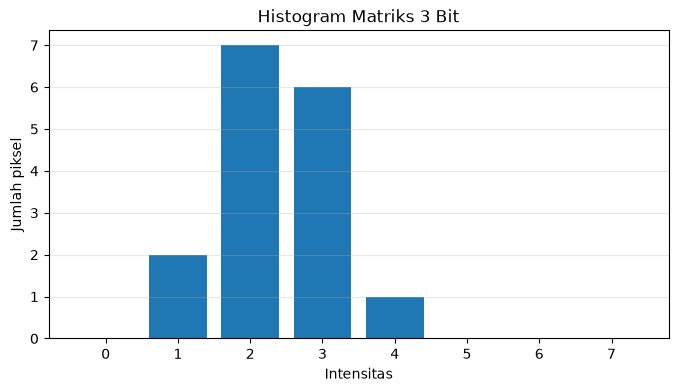

In [8]:
M = np.array([
    [1, 2, 2, 3],
    [2, 2, 3, 3],
    [1, 2, 3, 4],
    [2, 3, 3, 2]
])

hist = np.bincount(M.flatten(), minlength=8)

print("Histogram:")
for i, jumlah in enumerate(hist):
    print(f"Intensitas {i}: {jumlah} piksel")

plt.figure(figsize=(8, 4))
plt.bar(range(8), hist)
plt.xticks(range(8))
plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.title("Histogram Matriks 3 Bit")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [9]:
r_min = M.min()
r_max = M.max()

M_regang = np.rint(
    (M - r_min) / (r_max - r_min) * 7
).astype(int)

print("Matriks setelah peregangan:")
print(M_regang)

Matriks setelah peregangan:
[[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]


In [10]:
jumlah_piksel = M.size
hist = np.bincount(M.flatten(), minlength=8)

pdf = hist / jumlah_piksel
cdf = np.cumsum(pdf)
hasil_cdf = 7 * cdf
s = np.floor(hasil_cdf).astype(int)

tabel_eq = pd.DataFrame({
    "r": range(8),
    "n": hist,
    "PDF": pdf,
    "CDF": cdf,
    "7 x CDF": hasil_cdf,
    "s": s
})

print(tabel_eq.to_string(index=False))

M_eq = s[M]

print("\nMatriks setelah ekualisasi:")
print(M_eq)

 r  n    PDF    CDF  7 x CDF  s
 0  0 0.0000 0.0000   0.0000  0
 1  2 0.1250 0.1250   0.8750  0
 2  7 0.4375 0.5625   3.9375  3
 3  6 0.3750 0.9375   6.5625  6
 4  1 0.0625 1.0000   7.0000  7
 5  0 0.0000 1.0000   7.0000  7
 6  0 0.0000 1.0000   7.0000  7
 7  0 0.0000 1.0000   7.0000  7

Matriks setelah ekualisasi:
[[0 3 3 6]
 [3 3 6 6]
 [0 3 6 7]
 [3 6 6 3]]


In [11]:
# Negatif untuk r = 60
negatif = 255 - 60

# Kontras s = 1.4r - 30
kontras_120 = np.clip(1.4 * 120 - 30, 0, 255)
kontras_210 = np.clip(1.4 * 210 - 30, 0, 255)

# Koreksi gamma
gamma_06 = 255 * (100 / 255) ** 0.6
gamma_18 = 255 * (100 / 255) ** 1.8

print("Negatif r=60:", negatif)
print("Kontras r=120:", kontras_120)
print("Kontras r=210:", kontras_210)
print("Gamma 0.6, r=100:", round(gamma_06))
print("Gamma 1.8, r=100:", round(gamma_18))

Negatif r=60: 195
Kontras r=120: 138.0
Kontras r=210: 255.0
Gamma 0.6, r=100: 145
Gamma 1.8, r=100: 47


In [12]:
daftar_kondisi = [
    "teh_041.png",  # normal
    "teh_042.png",  # gelap
    "teh_043.png",  # terang
    "teh_044.png",  # kontras rendah
    "teh_045.png"   # bayangan
]

hasil_statistik = []

for nama in daftar_kondisi:
    img, gray, md, mb = baca_data(nama)

    data = statistik(gray)
    data["Citra"] = nama

    hasil_statistik.append(data)

tabel_statistik = pd.DataFrame(hasil_statistik)

tabel_statistik = tabel_statistik[
    ["Citra", "rerata", "simpangan_baku",
     "min", "maks", "persen_gelap", "persen_terang"]
]

print(tabel_statistik.to_string(index=False))

tabel_statistik.to_csv(
    "../hasil/b3_statistik_kondisi.csv",
    index=False
)

      Citra  rerata  simpangan_baku  min  maks  persen_gelap  persen_terang
teh_041.png   176.1            45.1   71   222           0.0           11.1
teh_042.png   129.7            44.0    9   191          13.2            0.0
teh_043.png   212.1            28.5  127   254           0.0           74.8
teh_044.png   157.2            17.5   83   208           0.0            0.0
teh_045.png   126.0            52.7   31   238           0.6            8.9


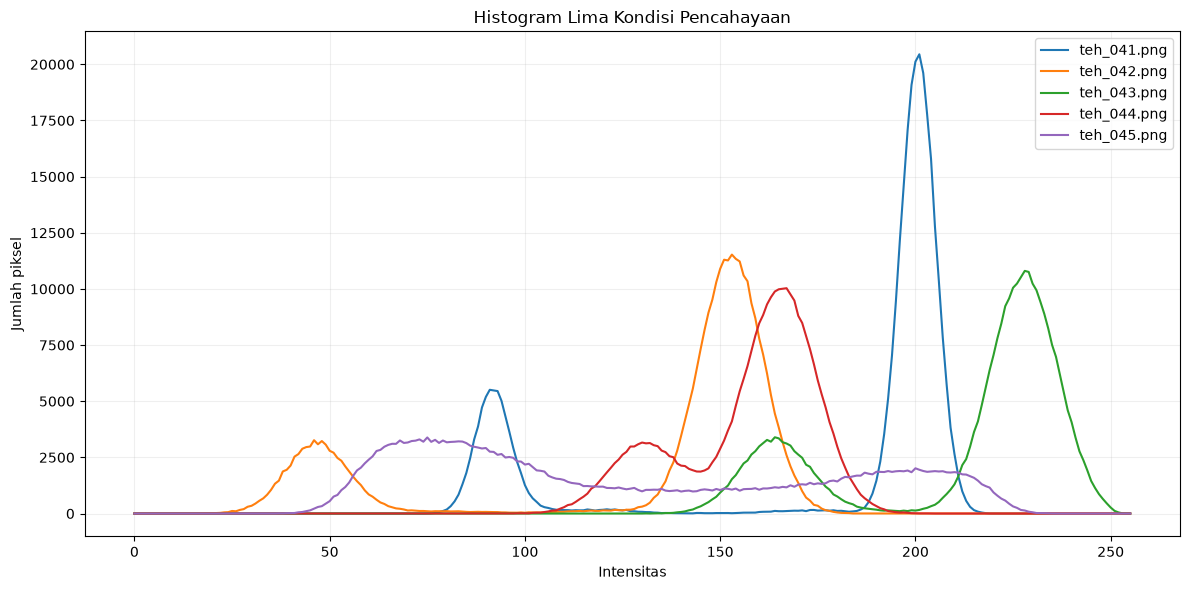

In [13]:
plt.figure(figsize=(12, 6))

for nama in daftar_kondisi:
    img, gray, md, mb = baca_data(nama)

    hist = cv2.calcHist(
        [gray], [0], None, [256], [0, 256]
    )

    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.title("Histogram Lima Kondisi Pencahayaan")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "../hasil/b3_histogram_5kondisi.png",
    dpi=200
)

plt.show()

In [14]:
daftar_ringan = [
    f"teh_{i:03d}.png"
    for i in range(21, 26)
]

hasil_ringan = []

for nama in daftar_ringan:
    img, gray, md, mb = baca_data(nama)

    data = statistik(gray)
    data["Citra"] = nama

    hasil_ringan.append(data)

tabel_ringan = pd.DataFrame(hasil_ringan)

tabel_ringan = tabel_ringan[
    ["Citra", "rerata", "simpangan_baku",
     "min", "maks", "persen_gelap", "persen_terang"]
]

print(tabel_ringan.to_string(index=False))

tabel_ringan.to_csv(
    "../hasil/b3_statistik_kelas_ringan.csv",
    index=False
)

      Citra  rerata  simpangan_baku  min  maks  persen_gelap  persen_terang
teh_021.png   173.9            39.2   77   219           0.0            2.2
teh_022.png   134.6            48.2   23   186          13.5            0.0
teh_023.png   202.3            28.0  131   248           0.0           70.3
teh_024.png   153.7            14.8   91   201           0.0            0.0
teh_025.png   122.1            50.0   26   237           0.9            5.1


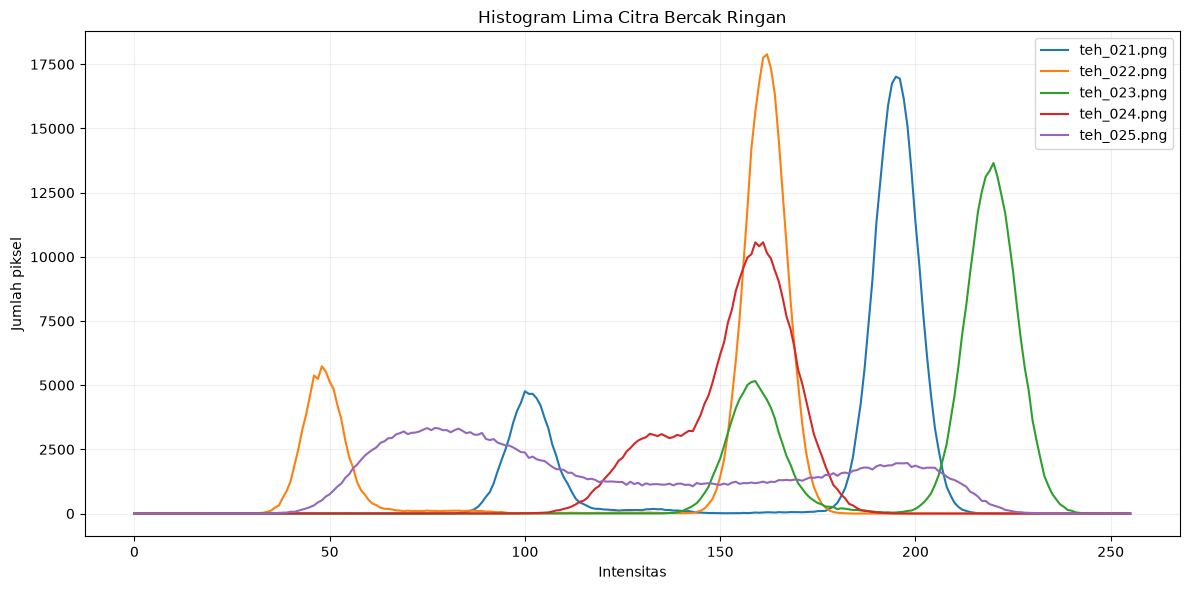

In [15]:
plt.figure(figsize=(12, 6))

for nama in daftar_ringan:
    img, gray, md, mb = baca_data(nama)

    hist = cv2.calcHist(
        [gray], [0], None, [256], [0, 256]
    )

    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.title("Histogram Lima Citra Bercak Ringan")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "../hasil/b3_histogram_kelas_ringan.png",
    dpi=200
)

plt.show()

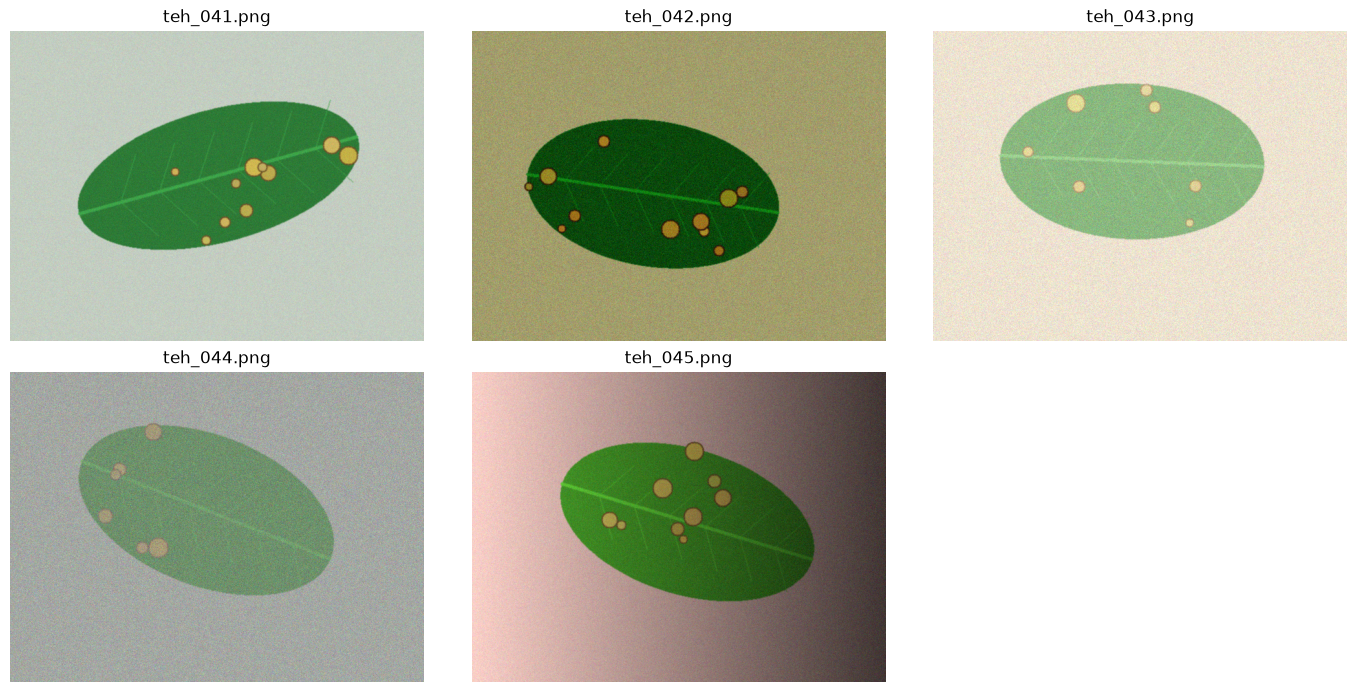

In [16]:
citra_panel = []
judul_panel = []

for nama in daftar_kondisi:
    img, gray, md, mb = baca_data(nama)

    citra_panel.append(img)
    judul_panel.append(nama)

tampil(
    citra_panel,
    judul_panel,
    baris=2,
    ukuran=(14, 7)
)

plt.savefig(
    "../hasil/b3_panel_kondisi.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [17]:
nama = "teh_045.png"

img, gray, md, mb = baca_data(nama)

def gamma_lut(g):
    lut = np.array([
        255 * (i / 255) ** g
        for i in range(256)
    ])

    return lut.clip(0, 255).astype(np.uint8)


rmin, rmax = np.percentile(gray, (2, 98))

if rmax == rmin:
    regang = gray.copy()
else:
    regang = np.clip(
        (gray.astype(np.float32) - rmin)
        / (rmax - rmin) * 255,
        0, 255
    ).astype(np.uint8)


hasil_perbaikan = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(
        gray, alpha=1.5, beta=-40
    ),
    "regang": regang,
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    ).apply(gray)
}

print("Eksperimen perbaikan citra:", nama)

Eksperimen perbaikan citra: teh_045.png


In [18]:
hasil_tabel = []

for metode, citra in hasil_perbaikan.items():
    kb = kontras_bercak(citra, md, mb)

    hasil_tabel.append({
        "Metode": metode,
        "Parameter": {
            "asli": "-",
            "negatif": "255 - r",
            "cerah+50": "+50",
            "kontras": "alpha=1.5, beta=-40",
            "regang": "Persentil 2 dan 98",
            "gamma0.5": "Gamma=0.5",
            "gamma1.8": "Gamma=1.8",
            "ekualisasi": "Global histogram equalization",
            "CLAHE": "clipLimit=2.0, tile=(8,8)"
        }[metode],
        "KB": round(kb, 2),
        "Simpangan baku": round(float(citra.std()), 2)
    })

tabel_perbaikan = pd.DataFrame(hasil_tabel)

print(tabel_perbaikan.to_string(index=False))

tabel_perbaikan.to_csv(
    "../hasil/b3_tabel_perbaikan.csv",
    index=False
)

    Metode                     Parameter   KB  Simpangan baku
      asli                             - 1.61           52.67
   negatif                       255 - r 1.61           52.67
  cerah+50                           +50 1.61           51.39
   kontras           alpha=1.5, beta=-40 1.61           74.87
    regang            Persentil 2 dan 98 1.65           82.00
  gamma0.5                     Gamma=0.5 1.45           37.54
  gamma1.8                     Gamma=1.8 1.88           57.09
ekualisasi Global histogram equalization 1.22           73.37
     CLAHE     clipLimit=2.0, tile=(8,8) 2.30           45.14


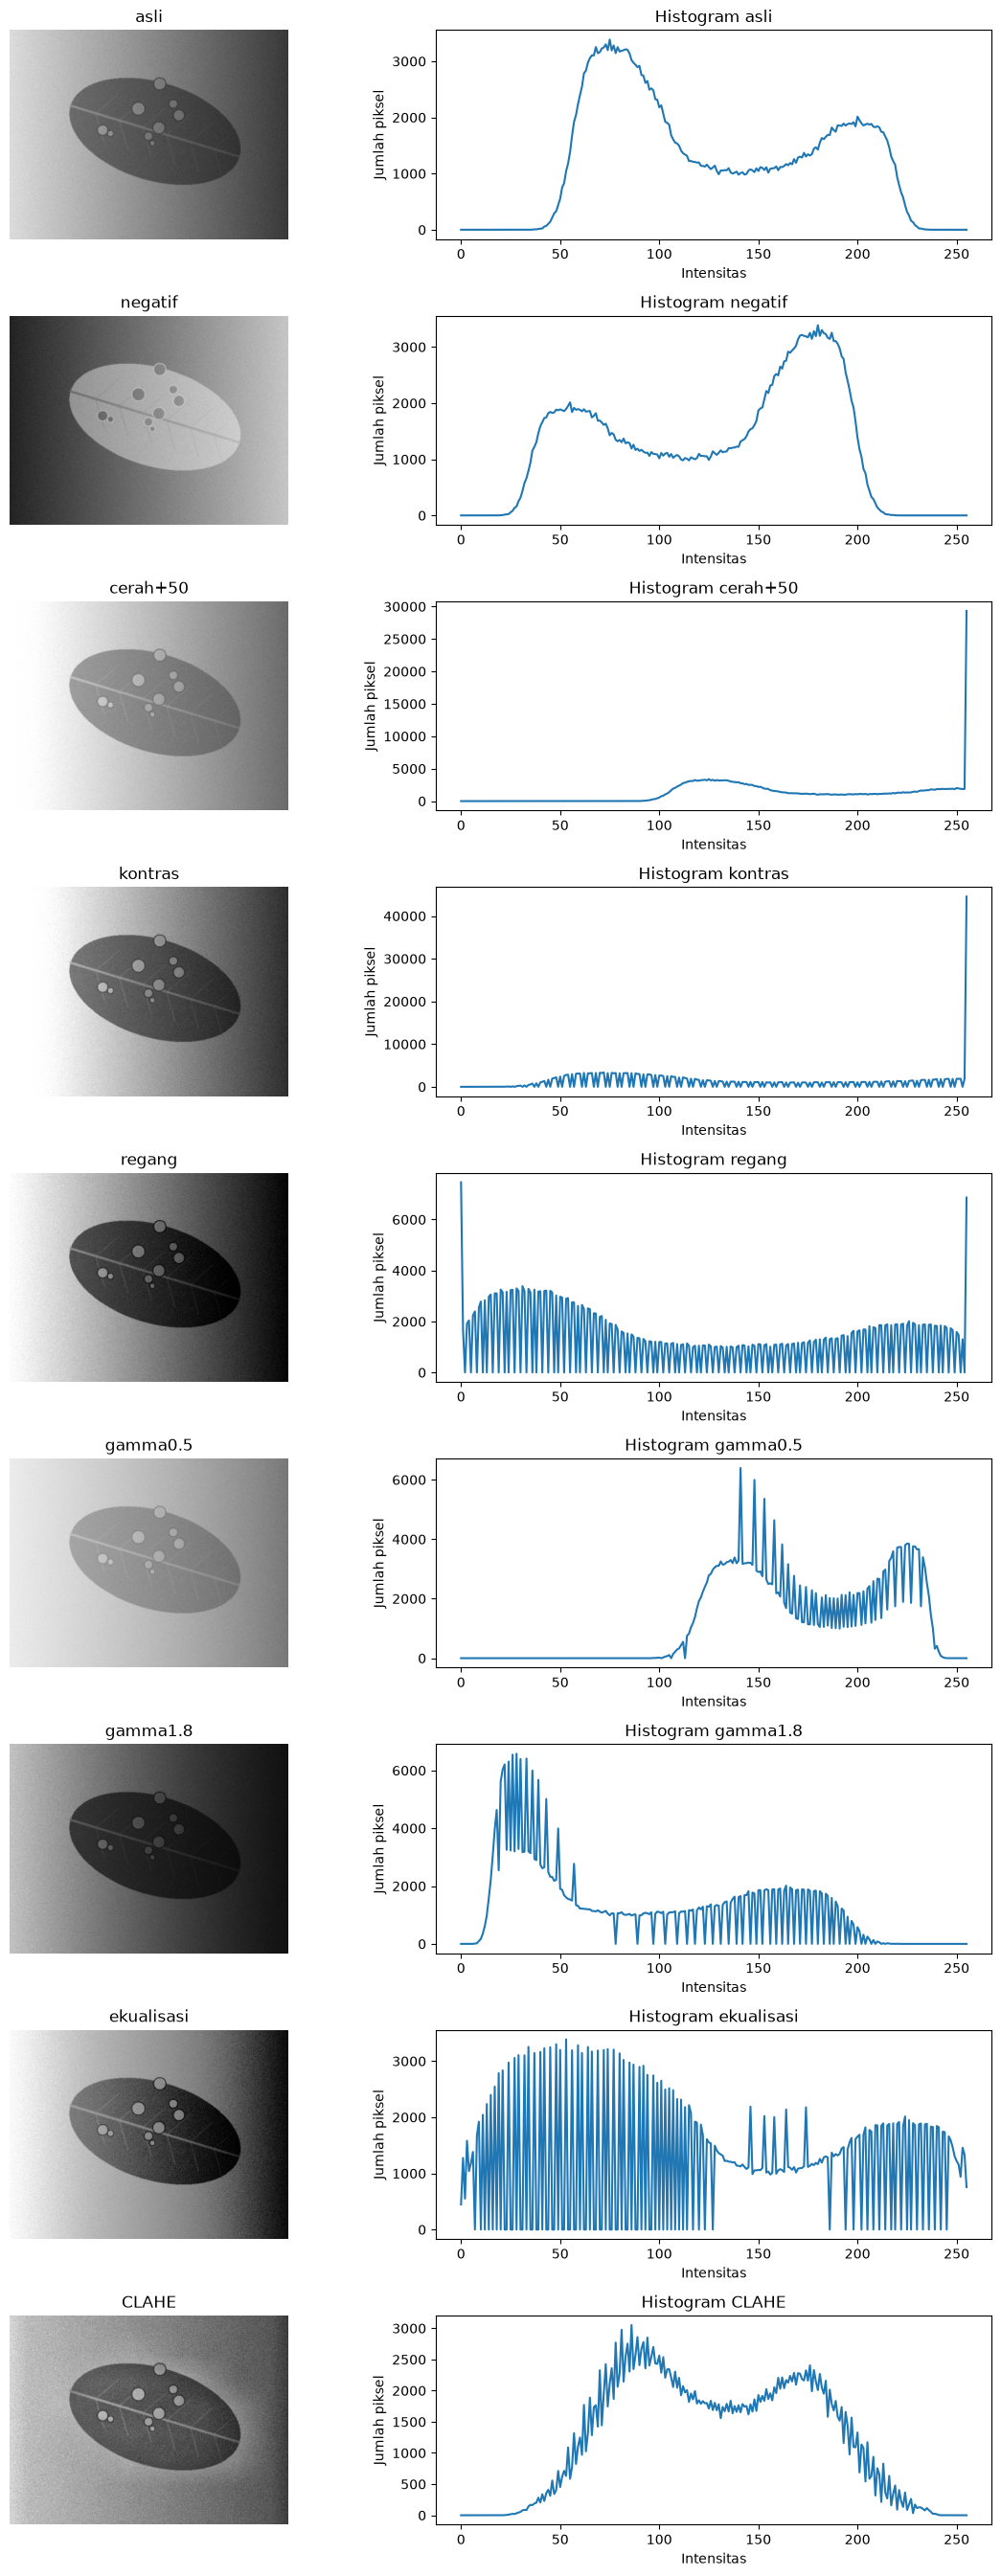

In [19]:
fig, axes = plt.subplots(
    len(hasil_perbaikan), 2,
    figsize=(12, 27)
)

for i, (metode, citra) in enumerate(hasil_perbaikan.items()):

    axes[i, 0].imshow(citra, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(metode)
    axes[i, 0].axis("off")

    hist = cv2.calcHist(
        [citra], [0], None, [256], [0, 256]
    )

    axes[i, 1].plot(hist)
    axes[i, 1].set_title(f"Histogram {metode}")
    axes[i, 1].set_xlabel("Intensitas")
    axes[i, 1].set_ylabel("Jumlah piksel")

plt.tight_layout()

plt.savefig(
    "../hasil/b3_perbandingan_perbaikan.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [20]:
hasil_clahe = []

for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:

        clahe = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        )

        citra = clahe.apply(gray)

        kb = kontras_bercak(citra, md, mb)

        hasil_clahe.append({
            "clipLimit": clip,
            "tileGridSize": tile,
            "KB": round(kb, 2),
            "Simpangan baku": round(float(citra.std()), 2)
        })

tabel_clahe = pd.DataFrame(hasil_clahe)

print(tabel_clahe.to_string(index=False))

tabel_clahe.to_csv(
    "../hasil/b3_eksperimen_clahe.csv",
    index=False
)

 clipLimit  tileGridSize   KB  Simpangan baku
       1.0             4 2.42           48.74
       1.0             8 2.32           48.27
       1.0            16 2.28           48.37
       2.0             4 2.52           46.30
       2.0             8 2.30           45.14
       2.0            16 2.08           46.12
       4.0             4 2.27           46.37
       4.0             8 2.00           42.70
       4.0            16 1.83           44.05


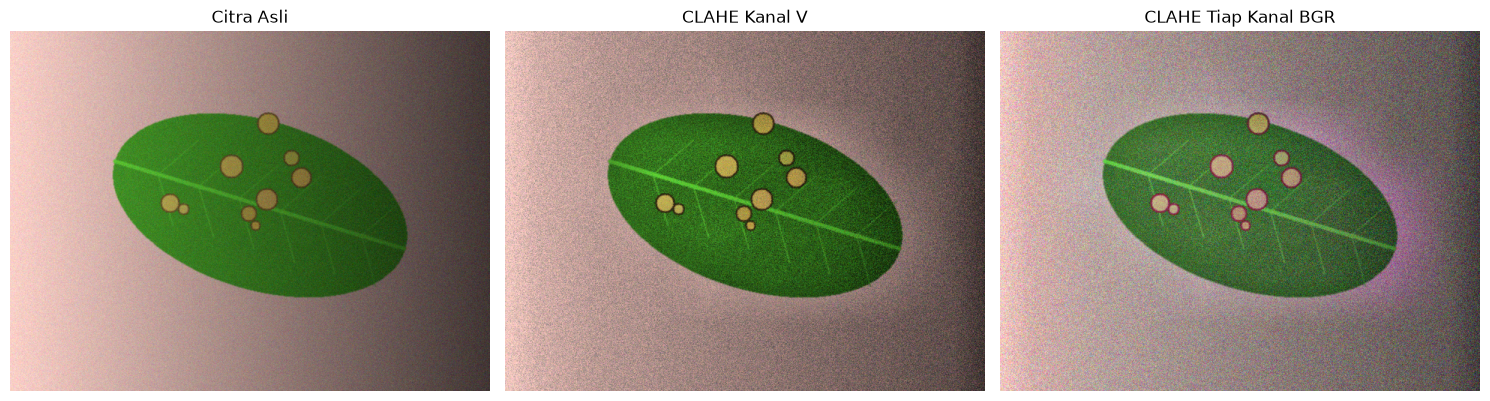

In [21]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# CLAHE pada kanal V dalam ruang warna HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])

via_v = cv2.cvtColor(
    hsv,
    cv2.COLOR_HSV2BGR
)

# CLAHE pada masing-masing kanal B, G, R
via_bgr = cv2.merge([
    clahe.apply(kanal)
    for kanal in cv2.split(img)
])

tampil(
    [img, via_v, via_bgr],
    ["Citra Asli", "CLAHE Kanal V", "CLAHE Tiap Kanal BGR"],
    baris=1,
    ukuran=(15, 5)
)

plt.savefig(
    "../hasil/b3_perbandingan_clahe_warna.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [22]:
gray_v = cv2.cvtColor(via_v, cv2.COLOR_BGR2GRAY)
gray_bgr = cv2.cvtColor(via_bgr, cv2.COLOR_BGR2GRAY)

kb_asli = kontras_bercak(gray, md, mb)
kb_v = kontras_bercak(gray_v, md, mb)
kb_bgr = kontras_bercak(gray_bgr, md, mb)

print(f"KB citra asli       : {kb_asli:.2f}")
print(f"KB CLAHE kanal V    : {kb_v:.2f}")
print(f"KB CLAHE tiap BGR   : {kb_bgr:.2f}")

KB citra asli       : 1.61
KB CLAHE kanal V    : 2.22
KB CLAHE tiap BGR   : 2.18


In [23]:
def perbaiki_citra(gray, kondisi):

    if kondisi == "gelap":
        return cv2.LUT(gray, gamma_lut(0.5))

    elif kondisi == "terang":
        return cv2.LUT(gray, gamma_lut(1.8))

    elif kondisi == "kontras_rendah":
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        return clahe.apply(gray)

    elif kondisi == "bayangan":
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        return clahe.apply(gray)

    else:
        return gray.copy()

In [24]:
pasangan = [
    ("gelap", "teh_042.png", "teh_022.png"),
    ("terang", "teh_043.png", "teh_023.png"),
    ("kontras_rendah", "teh_044.png", "teh_024.png"),
    ("bayangan", "teh_045.png", "teh_025.png")
]

hasil_uji = []

for kondisi, nama_berat, nama_ringan in pasangan:

    for kelas, nama in [
        ("berat", nama_berat),
        ("ringan", nama_ringan)
    ]:

        img, gray, md, mb = baca_data(nama)

        hasil = perbaiki_citra(gray, kondisi)

        kb_awal = kontras_bercak(gray, md, mb)
        kb_akhir = kontras_bercak(hasil, md, mb)

        hasil_uji.append({
            "Kondisi": kondisi,
            "Kelas": kelas,
            "Citra": nama,
            "KB sebelum": round(kb_awal, 2),
            "KB sesudah": round(kb_akhir, 2),
            "Perubahan KB": round(kb_akhir - kb_awal, 2)
        })

print(pd.DataFrame(hasil_uji).to_string(index=False))

pd.DataFrame(hasil_uji).to_csv(
    "../hasil/b3_uji_empat_kondisi.csv",
    index=False
)

       Kondisi  Kelas       Citra  KB sebelum  KB sesudah  Perubahan KB
         gelap  berat teh_042.png        4.33        3.40         -0.93
         gelap ringan teh_022.png        1.13        0.73         -0.40
        terang  berat teh_043.png        3.02        3.32          0.30
        terang ringan teh_023.png        3.29        3.61          0.32
kontras_rendah  berat teh_044.png        1.54        0.98         -0.56
kontras_rendah ringan teh_024.png        0.87        0.58         -0.29
      bayangan  berat teh_045.png        1.61        2.30          0.69
      bayangan ringan teh_025.png        0.05        0.18          0.13


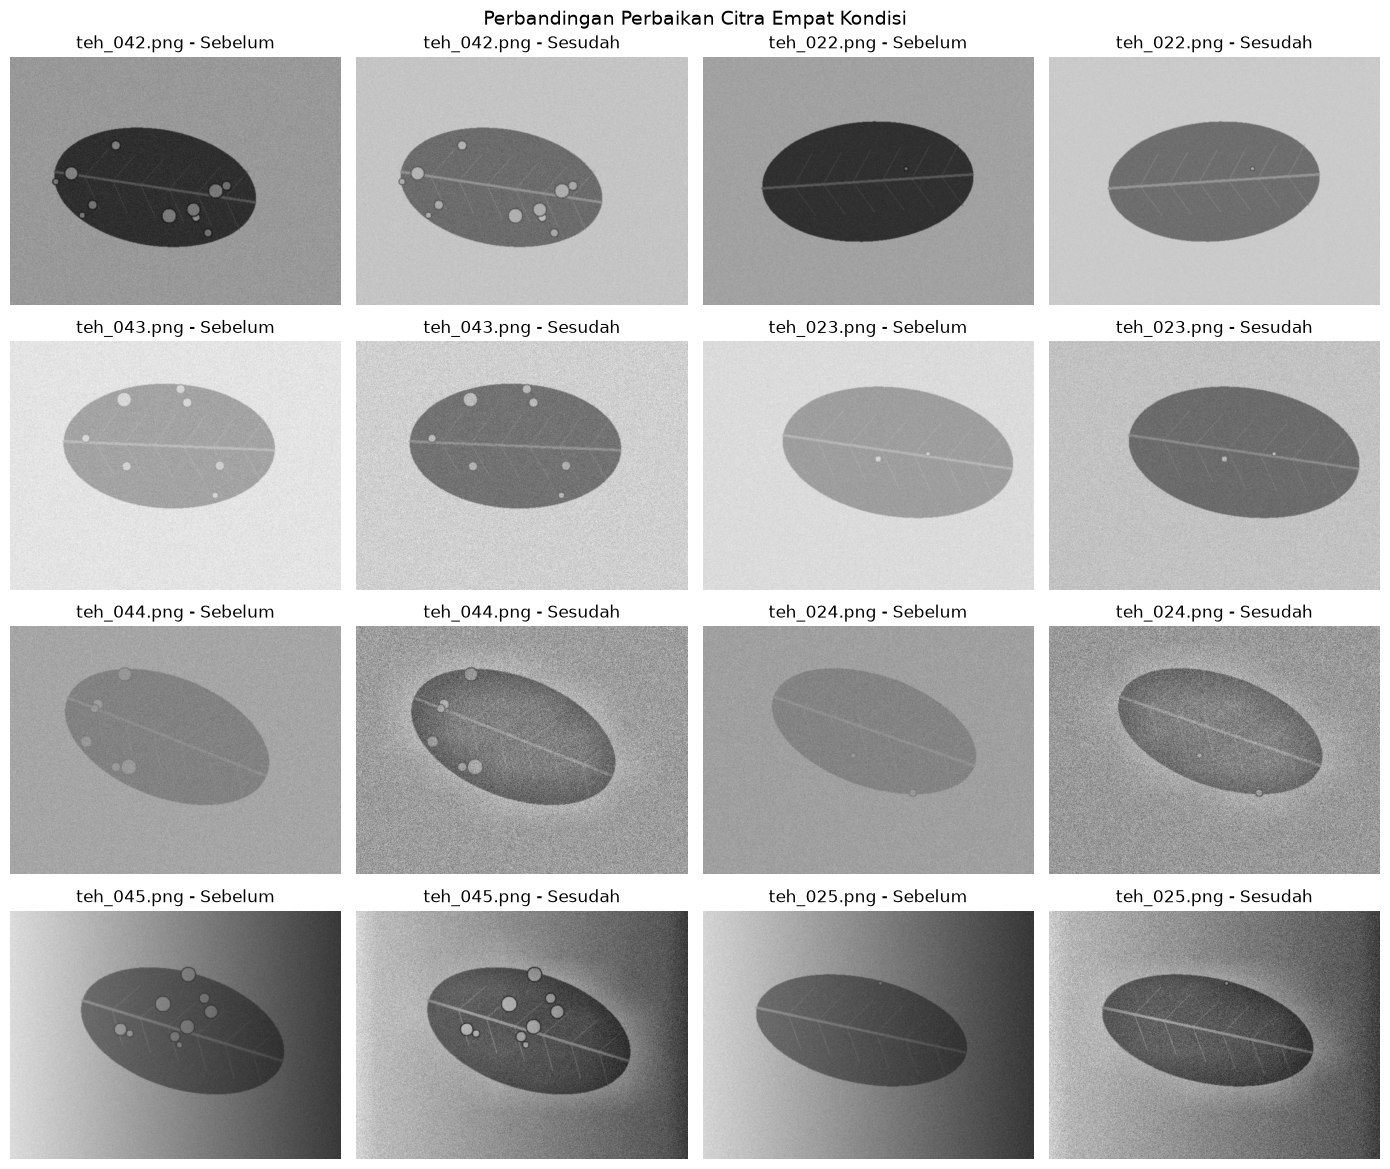

In [25]:
fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 12)
)

for i, (kondisi, nama_berat, nama_ringan) in enumerate(pasangan):

    for j, nama in enumerate([nama_berat, nama_ringan]):

        img, gray, md, mb = baca_data(nama)

        hasil = perbaiki_citra(gray, kondisi)

        axes[i, j * 2].imshow(
            gray, cmap="gray", vmin=0, vmax=255
        )
        axes[i, j * 2].set_title(
            f"{nama} - Sebelum"
        )
        axes[i, j * 2].axis("off")

        axes[i, j * 2 + 1].imshow(
            hasil, cmap="gray", vmin=0, vmax=255
        )
        axes[i, j * 2 + 1].set_title(
            f"{nama} - Sesudah"
        )
        axes[i, j * 2 + 1].axis("off")

plt.suptitle(
    "Perbandingan Perbaikan Citra Empat Kondisi",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "../hasil/b3_perbaikan_empat_kondisi.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()